In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import mlflow
import matplotlib.pyplot as plt
import cvxpy as cp
# %matplotlib widget
%load_ext autoreload
%autoreload 2

project_root = Path.cwd().parent.parent
print(project_root)

/Users/jack/Documents/01_Git/01_promotion/genSecSysId/python


In [2]:
from sysid.config import allow_file_store
allow_file_store()

# Set MLflow tracking URI
mlflow_uri = 'http://mlflowui.informatik.uni-stuttgart.de/'
mlflow.set_tracking_uri(mlflow_uri)

print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")

experiment_name = 'duffing-soft-12'

MLflow tracking URI: http://mlflowui.informatik.uni-stuttgart.de/


In [3]:
import torch
from sysid.models.factory import load_model
from sysid.config import Config
from sysid.data import DataNormalizer

# run_id = '3915a97b4fcd4c91a8101da09ccba3ce' # RegStable (best for Duffing oscillator)
run_id = 'c6f07cb26af44d86be4d2bebf3577741' # NotStable (best for Duffing oscillator)
print(f"Loading model from run {run_id}...")

# Models are logged as raw .pt files under artifact path "models" (not "model").
# mlflow.pytorch.log_model was never called, so mlflow.pytorch.load_model won't work.
outputs_dir = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="outputs")
models_dir  = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="models")

config = Config.from_yaml(os.path.join(outputs_dir, "config.yaml"))
model  = load_model(os.path.join(models_dir, "best_model.pt"), config)

normalizer_path = mlflow.artifacts.download_artifacts(
    run_id=run_id, artifact_path="models/normalizer.json"
)
normalizer = DataNormalizer.load(normalizer_path)

print(f"Model loaded: {type(model).__name__}")
print(model)

print(f"\nNormalizer loaded: {type(normalizer).__name__}")

Loading model from run c6f07cb26af44d86be4d2bebf3577741...


Model loaded: SimpleLure
SimpleLure(
  (lure): LureSystem(
    (Delta): DznActivation()
  )
)

Normalizer loaded: DataNormalizer


In [4]:
model.post_process()
alpha= float(1.0 / (1.0 + np.exp(-model.tau.detach().numpy())))

In [5]:
A = model.A.cpu().detach().numpy()
B = model.B.cpu().detach().numpy()
B2 = model.B2.cpu().detach().numpy()
C = model.C.cpu().detach().numpy()
D = model.D.cpu().detach().numpy()
D12 = model.D12.cpu().detach().numpy()
C2 = model.C2.cpu().detach().numpy()
D21 = model.D21.cpu().detach().numpy()

nx, nu, ny, nz = model.nx, model.nd, model.ne, model.nz


In [6]:
eps = 1e-6  # Small positive number for strict inequalities
P = cp.Variable((nx, nx), symmetric=True)
L = cp.Variable((nz, nx))
m = cp.Variable((nz, 1))
M = cp.diag(m)

# S_hat for optimizing s
S_hat = cp.Variable((1, 1))

# Constraints
constraints = []

# Main LMI: F <= -eps*I
F = cp.bmat(
    [
        [-(alpha**2) * P, np.zeros((nx, nu)), P @ C2.T + L.T, P @ A.T],
        [np.zeros((nu, nx)), -np.eye(nu), D21.T, B.T],
        [C2 @ P + L, D21, -2 * M, M @ B2.T],
        [A @ P, B, B2 @ M, -P],
    ]
)
nF = F.shape[0]
constraints.append(F << -eps * np.eye(nF))

# Locality constraints: [S_hat, li; li', P] >= eps*I for each row of L
for i in range(nz):
    li = L[i, :].reshape((1, -1), order="C")
    locality_lmi = cp.bmat([[S_hat, li], [li.T, P]])
    constraints.append(locality_lmi >> eps * np.eye(nx + 1))

# Objective
objective = cp.Minimize(S_hat)

# Solve
problem = cp.Problem(objective, constraints)
problem.solve(solver=cp.MOSEK)
print(f"Problem status: {problem.status}")

Problem status: optimal


In [7]:
def dzn(z):
    """Scalar deadzone: max(|z| - 1, 0) * sign(z)."""
    return np.maximum(np.abs(z) - 1, 0.0) * np.sign(z)

In [8]:
class LureModel:
    def __init__(self, A, B, B2, C, C2, D, D12, D21, psi=dzn):
        self.A = A
        self.B = B
        self.B2 = B2
        self.C = C
        self.C2 = C2
        self.D = D
        self.D12 = D12
        self.D21 = D21
        self.psi = psi
        self.nx = A.shape[0]
        self.nd = B.shape[1]
        self.ne = C.shape[0]
        self.nz = B2.shape[1]
    def step(self, x, u):
        u = np.asarray(u).reshape(-1)
        z = self.C2 @ x + self.D21 @ u
        w = self.psi(z)
        y_hat = self.C @ x + self.D @ u + self.D12 @ w
        x = self.A @ x + self.B @ u + self.B2 @ w
        return y_hat, x

    def simulate(self, x0, u_seq, apply_input_filter=False):
        X = [x0.copy()]
        Y = []
        u_filtered_seq = []
        for u in u_seq:
            u = np.asarray(u).reshape(-1)
            y_hat, x = self.step(X[-1], u)
            u_filtered_seq.append(u)
            X.append(x)
            Y.append(y_hat)
        return np.array(X), np.array(Y).reshape(-1), np.array(u_filtered_seq)

In [53]:
# find a controller F with u = F x such that the closed-loop is stable
import cvxpy as cp
eps = 1e-6
alphas = np.linspace(0, 0.99, 100)
Fs = []

for alpha in alphas:

    P = cp.Variable((nx,nx), symmetric=True)
    # substitution N = FP
    N = cp.Variable((nu, nx))
    # L = HP
    L = cp.Variable((nz, nx))
    m = cp.Variable((nz, 1))
    M = cp.diag(m)

    constraints = []

    Fb = cp.bmat(
        [
            [-alpha**2 *P, P@C2.T + N.T@D21.T + L.T, P@A.T + N.T@B.T],
            [C2@P + D21@N + L , -2*M, M@B2.T],
            [A@P + B@N, B2@M, -P]
        ]
    )
    nF = Fb.shape[0]
    constraints.append(Fb << -eps * np.eye(nF))

    # Locality constraints: [S_hat, li; li', P] >= eps*I for each row of L
    for i in range(nz):
        li = L[i, :].reshape((1, -1), order="C")
        locality_lmi = cp.bmat([[np.array([[1.0]]), li], [li.T, P]])
        constraints.append(locality_lmi >> eps * np.eye(nx + 1))

    objective = cp.Minimize(cp.norm(N))
    # Solve
    problem = cp.Problem(objective, constraints)    
    # print(f"Solving SDP with {len(constraints)} constraints using MOSEK...")
    try:
        problem.solve(solver=cp.MOSEK, verbose=False)
    except:
        print(f'Regional stability mosek failure = {alpha}.')
        continue
    if problem.status != cp.OPTIMAL:
        print(f'Regional stability failure = {alpha}.')
        continue

    Fs.append(N.value @ np.linalg.inv(P.value))
    print(f"alpha = {alpha:.3f}, status = {problem.status}, |N|_F = {np.linalg.norm(N.value, 'fro'):.4f}")

Regional stability mosek failure = 0.0.
Regional stability mosek failure = 0.01.
Regional stability mosek failure = 0.02.
Regional stability mosek failure = 0.03.
Regional stability mosek failure = 0.04.
Regional stability failure = 0.05.
Regional stability mosek failure = 0.06.
Regional stability mosek failure = 0.07.
Regional stability mosek failure = 0.08.
Regional stability failure = 0.09.
Regional stability mosek failure = 0.1.
Regional stability mosek failure = 0.11.
Regional stability mosek failure = 0.12.
Regional stability mosek failure = 0.13.
Regional stability mosek failure = 0.14.
Regional stability mosek failure = 0.15.
Regional stability mosek failure = 0.16.
Regional stability mosek failure = 0.17.
Regional stability mosek failure = 0.18.
Regional stability mosek failure = 0.19.
Regional stability mosek failure = 0.2.
Regional stability mosek failure = 0.21.
Regional stability mosek failure = 0.22.
alpha = 0.230, status = optimal, |N|_F = 8.5580
alpha = 0.240, status = 

In [54]:
def plot_trajectory(axs, X, label = ''):
    axs[0].plot(X[:,0], X[:,1], '.-', label=label)
    axs[0].set_xlabel('$x_1$')
    axs[0].set_ylabel('$x_2$')
    axs[0].axis('equal')
    axs[0].legend()
    # axs[0].set_xlim([-4.5, 4.5])
    # axs[0].set_ylim([-4.5, 4.5])

    axs[1].plot(np.arange(len(X)), X[:,0], '.-', label=r'$x_1$')
    axs[1].plot(np.arange(len(X)), X[:,1], '.-', label=r'$x_2$')
    axs[1].set_xlabel('time step')
    axs[1].set_ylabel('output $y$')
    axs[1].legend()
    # axs[1].set_ylim([-4.5, 4.5])
    axs[1].grid()

Initial state = [ 3.14159265 -4.        ], F = [[-3.05533522e-16 -3.16165910e-16]]


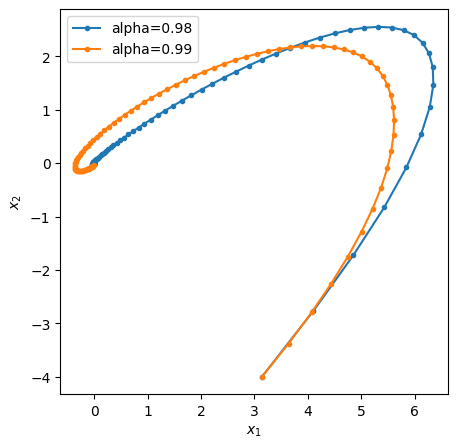

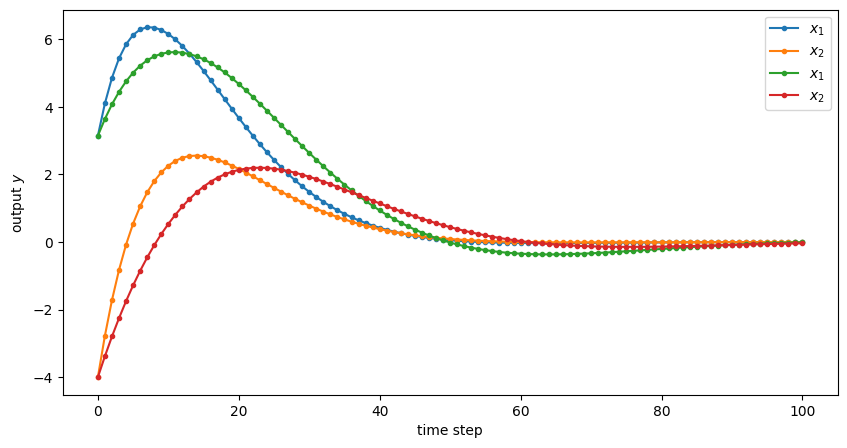

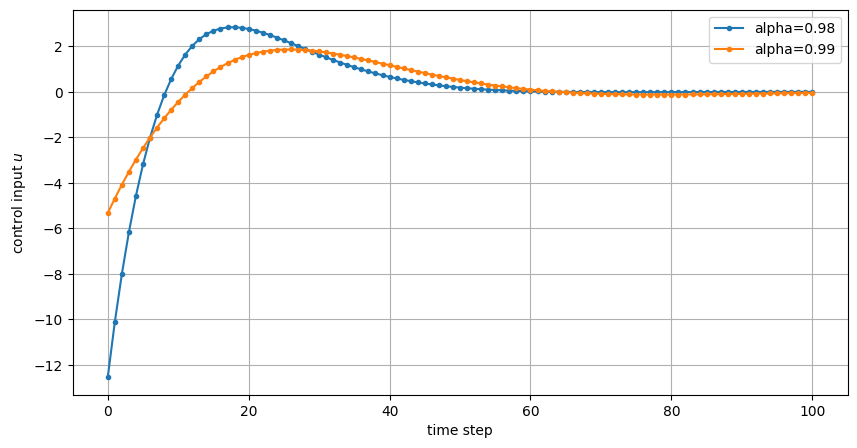

In [55]:
# check closed loop with u = Fx as controller for different alpha values
# once the loop is closed there is no external input anymore, so we only look at convergence from random initial conditions
# A, B, B2, C, C2, D, D12, D21,

fig1, ax1 = plt.subplots(1,1, figsize=(5,5))
fig2, ax2 = plt.subplots(1,1, figsize=(10,5))
fig3, ax3 = plt.subplots(1,1, figsize=(10,5))
# ax3.set_ylim([-4.5, 4.5])
ax3.set_xlabel('time step')
ax3.set_ylabel('control input $u$')
ax3.grid()

# F = Fs[-2]
x0 = np.random.randn(nx)
x0[0] = np.pi
x0[1] = -4.0  # set initial velocity to zero
print(f"Initial state = {x0}, F = {F}")
for F, alpha in zip(Fs[-2:], alphas[-2:]):
    model_cl = LureModel(
        A + B @ F,
        np.zeros((nx, nu)),  # no external input
        B2,
        C,
        C2,
        np.zeros((ny, nu)),  # no external input
        D12,
        D21,
        psi=dzn
    )
    X, Y, _ = model_cl.simulate(x0, np.zeros((100,nu)))
    us = np.array([F @ x_i for x_i in X])
    plot_trajectory([ax1, ax2], X, label=f'alpha={alpha:.2f}')
    ax3.plot(np.arange(len(us)), us, '.-', label=f'alpha={alpha:.2f}')

ax3.legend()



# Test the designed controller on the true continuous time ode


In [56]:
DELTA_D = 0.3   # damping coefficient
TS      = 0.05  # sample time [s]


In [ ]:
from scipy.integrate import solve_ivp

def duffing_ct(t, x, u=0.0, delta_d=DELTA_D):
    """Continuous-time Duffing RHS: q'' = -delta_d*q' - q + q^3 + u."""
    q, dq = x
    ddq = -delta_d * dq - q + q**3 + u
    return [dq, ddq]


def duffing_dt(x, u=0.0, Ts=TS, delta_d=DELTA_D):
    """One RK4 step of the Duffing system (ZOH input)."""
    f  = lambda t, xv: duffing_ct(t, xv, u=u, delta_d=delta_d)
    sol = solve_ivp(f, [0, Ts], x, method='RK45',
                    rtol=1e-5, atol=1e-7, dense_output=False)
    return sol.y[:, -1]

def simulate(x0, u_seq, Ts=TS, delta_d=DELTA_D):
    """Simulate the discrete-time Duffing system.
    Returns state trajectory X (T+1, 2), output y = q, and diverged flag.
    Stops early if |state| > diverge_thresh.
    """
    T = len(u_seq)
    X = [np.array(x0, dtype=float)]
    for k in range(T):
        xnew = duffing_dt(X[-1], u=u_seq[k], Ts=Ts, delta_d=delta_d)
        X.append(xnew)
    X = np.array(X)
    y = X[:, 0]
    return X, y[:-1]

def simulate_controlled(x0, F, T=50, Ts=TS, delta_d=DELTA_D):
    """Simulate the discrete-time Duffing system with state feedback control u = Fx.
    Returns state trajectory X (T+1, 2), output y = q, and diverged flag.
    Stops early if |state| > diverge_thresh.
    """
    X = [np.array(x0, dtype=float)]
    u_seq = []
    for k in range(T):
        u = F @ X[-1]
        u_seq.append(u)
        xnew = duffing_dt(X[-1], u=u.squeeze(), Ts=Ts, delta_d=delta_d)
        X.append(xnew)
    X = np.array(X)
    y = X[:, 0]
    return X, y[:-1], np.array(u_seq)


In [73]:
F = Fs[-2]  # use the last controller for simulation

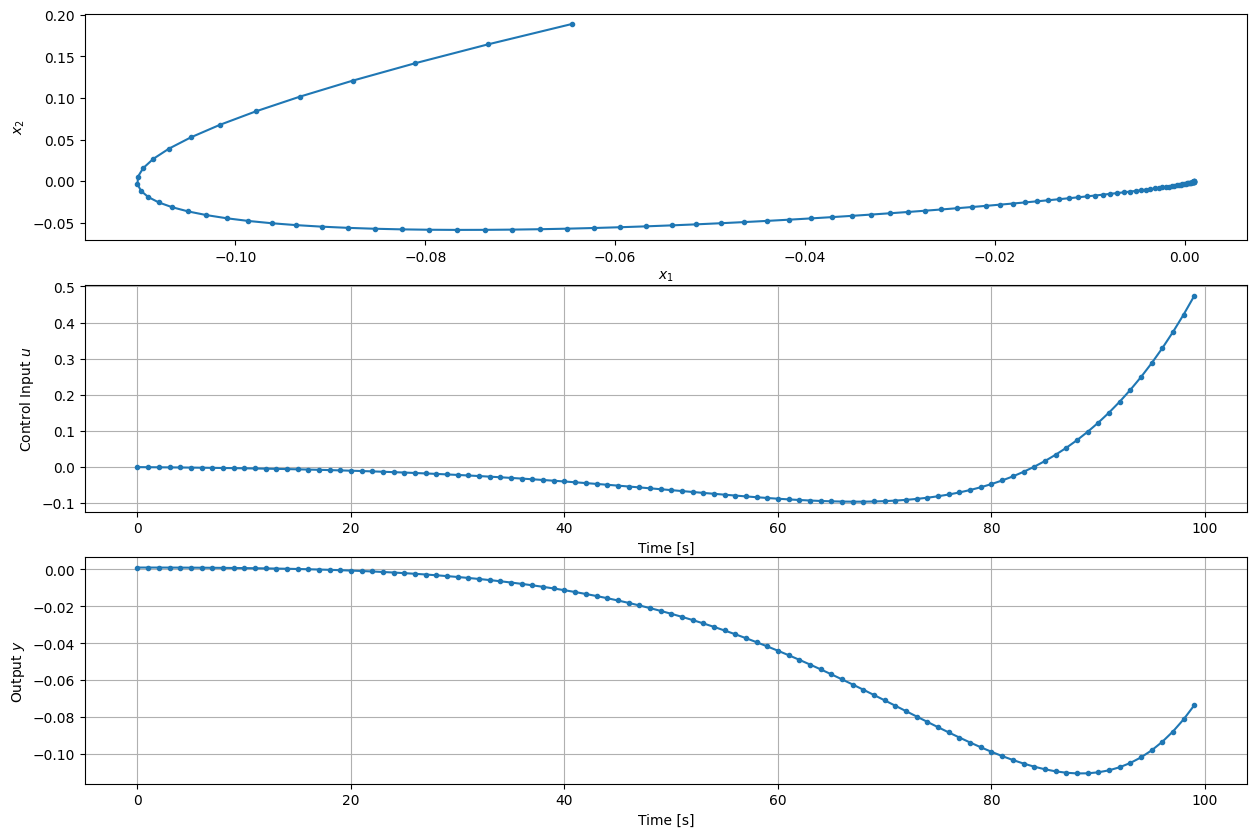

In [78]:
x0 = np.array([0.001, 0.0])
X, y, u = simulate_controlled(x0, F, T=100)

rows = 3
fig, ax = plt.subplots(3, 1, figsize=(rows * 5, 10))
ax[0].plot(X[:, 0], X[:, 1], '.-')
ax[0].set_xlabel('$x_1$')
ax[0].set_ylabel('$x_2$')
ax[1].plot(u, '.-')
ax[1].set_xlabel('Time [s]')
ax[1].set_ylabel('Control Input $u$')
ax[1].grid()
ax[2].plot(y, '.-')
ax[2].set_xlabel('Time [s]')
ax[2].set_ylabel('Output $y$')
ax[2].grid()


In [79]:
# test controller on lure model with least squares solution for nonlinearity

lure_params_path = os.path.join('datasets', 'id', 'lure_model_params.npz')
load_lure_params = np.load(lure_params_path)

In [83]:
A_lure = load_lure_params['A']
B_lure = load_lure_params['B']
B2_lure = load_lure_params['B2']
C_lure = load_lure_params['C']
C2_lure = load_lure_params['C2']
D_lure = load_lure_params['D']
D12_lure = load_lure_params['D12']
D21_lure = load_lure_params['D21']

print(f'A = {A_lure}, B = {B_lure}, B2 = {B2_lure}, C = {C_lure}, C2 = {C2_lure}, D = {D_lure}, D12 = {D12_lure}, D21 = {D21_lure}')

A = [[ 1.     0.05 ]
 [-0.05   0.985]], B = [[0.  ]
 [0.05]], B2 = [[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.00015024 0.00047411 0.00114815 0.00202735 0.00315616 0.00456669
  0.00619063 0.0081094  0.01024613 0.01265505 0.01532539 0.01820006
  0.02143235 0.02473992 0.02857361 0.03225986 0.0367963  0.04058483
  0.04677885 0.        ]], C = [[1. 0.]], C2 = [[13.33333333  0.        ]
 [ 6.66666667  0.        ]
 [ 4.44444444  0.        ]
 [ 3.33333333  0.        ]
 [ 2.66666667  0.        ]
 [ 2.22222222  0.        ]
 [ 1.9047619   0.        ]
 [ 1.66666667  0.        ]
 [ 1.48148148  0.        ]
 [ 1.33333333  0.        ]
 [ 1.21212121  0.        ]
 [ 1.11111111  0.        ]
 [ 1.02564103  0.        ]
 [ 0.95238095  0.        ]
 [ 0.88888889  0.        ]
 [ 0.83333333  0.        ]
 [ 0.78431373  0.        ]
 [ 0.74074074  0. 

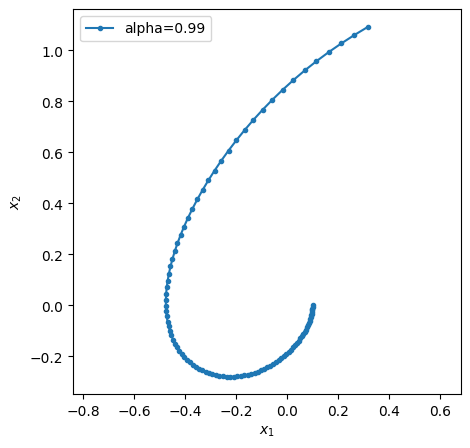

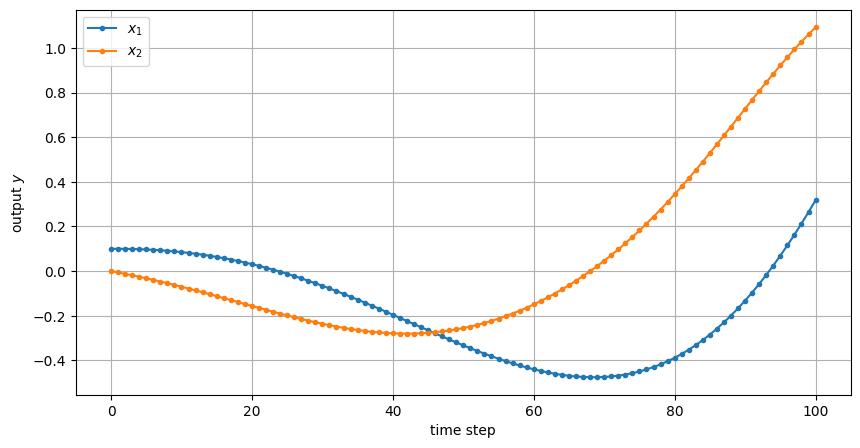

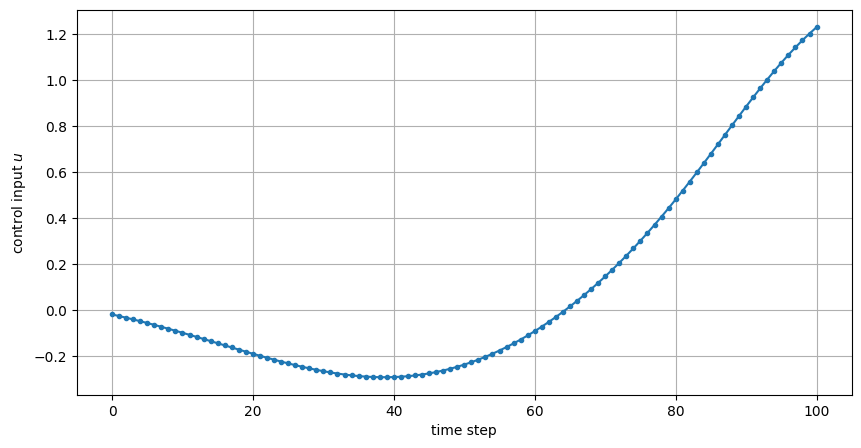

In [89]:
fig1, ax1 = plt.subplots(1,1, figsize=(5,5))
fig2, ax2 = plt.subplots(1,1, figsize=(10,5))
fig3, ax3 = plt.subplots(1,1, figsize=(10,5))
# ax3.set_ylim([-4.5, 4.5])
ax3.set_xlabel('time step')
ax3.set_ylabel('control input $u$')
ax3.grid()

# F = Fs[-2]
x0 = np.random.randn(nx)
x0[0] = 0.1
x0[1] = 0.0  # set initial velocity to zero

for F, alpha in zip(Fs[-1:], alphas[-1:]):
    model_lure_cl = LureModel(
        A_lure + B_lure @ F,
        np.zeros((nx, nu)),  # no external input
        B2_lure,
        C_lure,
        C2_lure,
        np.zeros((ny, nu)),  # no external input
        D12_lure,
        D21_lure,
        psi=dzn
    )
    X, Y, _ = model_lure_cl.simulate(x0, np.zeros((100,nu)))
    us = np.array([F @ x_i for x_i in X])
    plot_trajectory([ax1, ax2], X, label=f'alpha={alpha:.2f}')
    ax3.plot(np.arange(len(us)), us, '.-', label=f'alpha={alpha:.2f}')